# 06 — Gaussian Process Regression (GPR)

This notebook adds Gaussian Process Regression (GPR)

**Research purpose:** evaluate whether a Gaussian Process can forecast monthly lithium carbonate prices and provide model-based predictive uncertainty.

The notebook evaluates 1-, 3-, 6-, and 12-month horizons using:
- A univariate feature set: 12 monthly lags of the lithium carbonate target.
- A multivariate feature set: 3 monthly lags of the target plus up to five market predictors selected using training data only.

The multivariate feature screen is deliberately limited to five base predictors because GPR can become computationally and statistically difficult in a high-dimensional feature space, especially with only about 200 monthly target observations.

GPR is not guaranteed to outperform the simpler models. Compare its held-out RMSE/MAE with Notebooks 03 and 04.

## 1. Setup and data loading

In [28]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF, WhiteKernel
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

DATA_FILE = Path("../../Data/lithium_consolidated_monthly.csv")
TARGET = "Selected lithium carbonate price (CNY/t)"
JAPAN_INDEX = "Japan, Import Prices, Yen Basis, Lithium Carbonates, Index, 2020 = 100"
RANDOM_STATE = 42

df = pd.read_csv(DATA_FILE)
df["Month"] = pd.to_datetime(df["Month"])
df = (df.sort_values("Month")
        .drop_duplicates("Month")
        .set_index("Month")
        .asfreq("MS"))
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")

print("Rows:", len(df))
print("Target observations:", df[TARGET].notna().sum())
print("Date range:", df.index.min(), "to", df.index.max())

Rows: 209
Target observations: 209
Date range: 2009-06-01 00:00:00 to 2026-10-01 00:00:00


## 2. Define forecasting and evaluation functions

All features are lagged, so the model only receives information available before the forecast target month. Missing predictor values are imputed inside the pipeline; the imputer and scaler are fitted on training data only.

The Gaussian Process uses a constant-amplitude RBF kernel plus a white-noise component. `normalize_y=True` stabilizes fitting when prices have a large numerical scale. The returned predictive standard deviation is the GPR model's estimated uncertainty; it is not automatically a calibrated 95% interval.

In [45]:
def make_supervised(horizon=1, n_lags=3, exog_cols=None):
    X = pd.DataFrame(index=df.index)

    for lag in range(1, n_lags + 1):
        X[f"Target_lag_{lag}"] = df[TARGET].shift(lag)

    if exog_cols is not None:
        for col in exog_cols:
            for lag in range(1, n_lags + 1):
                X[f"{col}_lag_{lag}"] = df[col].shift(lag)

    # h=1 predicts this row's month from prior-month features;
    # h=3 predicts two months beyond the feature-origin month.
    y = df[TARGET].shift(-(horizon - 1))
    valid = y.notna()
    return X.loc[valid], y.loc[valid]


def split_time(X, y, train_fraction=0.80):
    cut = int(len(X) * train_fraction)
    return X.iloc[:cut], X.iloc[cut:], y.iloc[:cut], y.iloc[cut:]


def make_gpr():
    kernel = (
    ConstantKernel(1.0, (1e-2, 1e2))
    * Matern(
        length_scale=1.0,
        length_scale_bounds=(1e-2, 1e2),
        nu=1.5
    )
    + WhiteKernel(
        noise_level=0.1,
        noise_level_bounds=(1e-5, 1e1)
    )
)
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("gpr", GaussianProcessRegressor(
            kernel=kernel,
            normalize_y=True,
            n_restarts_optimizer=2,
            random_state=RANDOM_STATE
        ))
    ])


def score_predictions(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
        "R2": r2_score(y_true, y_pred)
    }

## 3. Select a compact multivariate predictor set

The eligible base predictors exclude the target and duplicate/invalid target-price columns. Predictors must have at least 60 observed monthly values. The shorter-history Japan inventory, shipments, and production columns are excluded because their longer-history counterparts are retained.

For each horizon, the five predictors with the strongest absolute correlation to the future target are selected using the training period only. This avoids selecting features based on the held-out test period.

In [46]:
EXCLUDED = {
    TARGET,
    "Selected target source",
    "Lithium carbonate price (CNY/metric tonne)",
    "China spot lithium carbonate price (CNY/t) - CSV",
    "China spot price open (CNY/t) - CSV",
    "China spot price high (CNY/t) - CSV",
    "China spot price low (CNY/t) - CSV",
    "China spot price volume (CSV)",
    "China spot price change (%) - CSV"
}
DUPLICATE_PREDICTORS = {
    "Japan lithium battery inventory (thousands)",
    "Japan lithium battery shipments (thousands)",
    "Japan lithium battery production (thousands)"
}

ALL_PREDICTORS = [
    c for c in df.select_dtypes(include=np.number).columns
    if c not in EXCLUDED and c not in DUPLICATE_PREDICTORS
]
coverage = df[ALL_PREDICTORS].notna().sum()
eligible_predictors = [c for c in ALL_PREDICTORS if coverage[c] >= 60]

print("Eligible base predictors:", len(eligible_predictors))
print("Japan import-price index available:", JAPAN_INDEX in eligible_predictors)

Eligible base predictors: 18
Japan import-price index available: True


## 4. Fit GPR across forecast horizons

The univariate GPR uses 12 target-price lags. The multivariate GPR uses 3 target-price lags and 3 lags of the five training-selected market predictors.

A chronological 80/20 split is used. The final test set is not used to choose the multivariate predictors or fit the model.

In [47]:
HORIZONS = [1, 3, 6, 12]
results = []
predictions = {}

for h in HORIZONS:
    # Univariate GPR
    X_uni, y_uni = make_supervised(horizon=h, n_lags=12, exog_cols=None)
    Xtr, Xte, ytr, yte = split_time(X_uni, y_uni)
    gpr_uni = make_gpr()
    gpr_uni.fit(Xtr, ytr)
    pred, std = gpr_uni.predict(Xte, return_std=True)

    results.append({
        "Feature set": "Univariate (12 target lags)",
        "Horizon (months)": h,
        **score_predictions(yte, pred),
        "Mean predictive SD": float(np.mean(std)),
        "Selected predictors": "Target lags only"
    })
    predictions[("Univariate (12 target lags)", h)] = (yte, pred, std, gpr_uni)

    # Select predictors using training period only
    X_all, y_all = make_supervised(horizon=h, n_lags=3, exog_cols=None)
    Xtr_all, Xte_all, ytr_all, yte_all = split_time(X_all, y_all)
    origin_index = Xtr_all.index

    # Correlate each candidate's latest available value with the
    # future target; this selection is confined to training rows.
    train_target = ytr_all
    corr_scores = {}
    for col in eligible_predictors:
        lagged = df[col].shift(1).reindex(origin_index)
        pair = pd.concat([lagged.rename("x"), train_target.rename("y")], axis=1).dropna()
        if len(pair) >= 30 and pair["x"].nunique() > 1:
            corr_scores[col] = pair["x"].corr(pair["y"])

    selected = [
        col for col, value in sorted(
            corr_scores.items(),
            key=lambda item: abs(item[1]) if pd.notna(item[1]) else -1,
            reverse=True
        )[:5]
    ]

    X_multi, y_multi = make_supervised(horizon=h, n_lags=3, exog_cols=selected)
    Xtr, Xte, ytr, yte = split_time(X_multi, y_multi)
    gpr_multi = make_gpr()
    gpr_multi.fit(Xtr, ytr)
    pred, std = gpr_multi.predict(Xte, return_std=True)

    results.append({
        "Feature set": "Multivariate (3 lags; top 5 predictors)",
        "Horizon (months)": h,
        **score_predictions(yte, pred),
        "Mean predictive SD": float(np.mean(std)),
        "Selected predictors": "; ".join(selected)
    })
    predictions[("Multivariate (3 lags; top 5 predictors)", h)] = (yte, pred, std, gpr_multi)

results = pd.DataFrame(results).sort_values(["Horizon (months)", "RMSE"])
display(results)

,Feature set,Horizon (months),MAE,RMSE,R2,Mean predictive SD,Selected predictors
0,Univariate (12 target lags),1,24111.210577,43464.356708,0.430448,63739.615276,Target lags only
1,Multivariate (3 lags; top 5 predictors),1,220086.772295,240667.025626,-16.462251,267430.710706,US CPI (1982–84 = 100); SQM share price (USD/A...
2,Univariate (12 target lags),3,40672.690234,59139.534079,-0.054442,99300.946478,Target lags only
3,Multivariate (3 lags; top 5 predictors),3,69731.676723,78952.057063,-0.879291,190557.619620,"US CPI (1982–84 = 100); US GDP (USD billion, c..."
5,Multivariate (3 lags; top 5 predictors),6,41287.307716,57284.605497,-0.058910,189411.767606,Albemarle share price (USD/share); Tesla share...
4,Univariate (12 target lags),6,52464.676543,73549.199227,-0.745578,145383.056147,Target lags only
6,Univariate (12 target lags),12,49018.745168,62767.518354,-0.675975,144731.457768,Target lags only
7,Multivariate (3 lags; top 5 predictors),12,59280.229213,67849.823681,-0.958372,161397.477610,CNY/USD exchange-rate series (source quote); L...


## 5. Compare univariate and multivariate GPR

Feature set,Multivariate (3 lags; top 5 predictors),Univariate (12 target lags)
Horizon (months),,
1,240667.025626,43464.356708
3,78952.057063,59139.534079
6,57284.605497,73549.199227
12,67849.823681,62767.518354


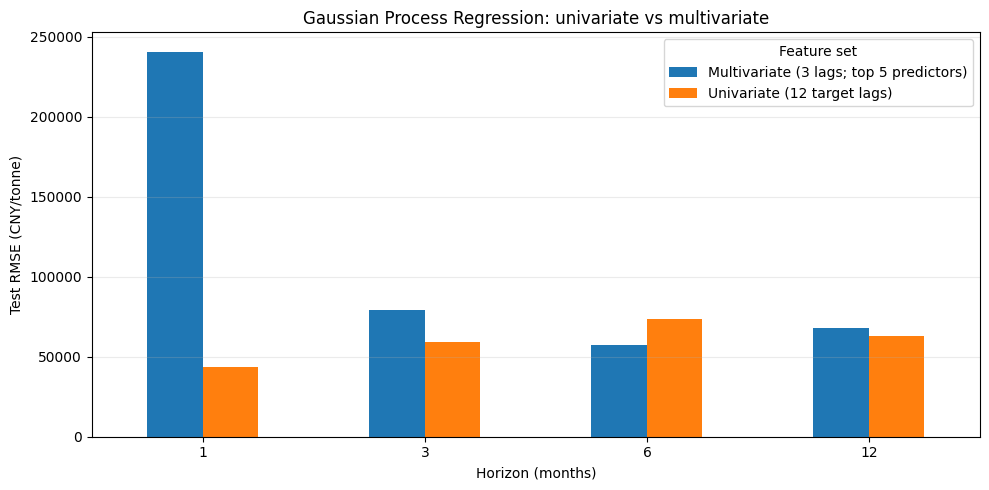

In [48]:
pivot = results.pivot(
    index="Horizon (months)",
    columns="Feature set",
    values="RMSE"
)
display(pivot)

ax = pivot.plot(kind="bar", figsize=(10, 5))
ax.set_ylabel("Test RMSE (CNY/tonne)")
ax.set_title("Gaussian Process Regression: univariate vs multivariate")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 6. Plot one-month forecast with GPR uncertainty

The shaded region is the approximate 95% interval `prediction ± 1.96 × predictive standard deviation`. It represents the Gaussian Process model's predictive distribution under its kernel assumptions. Check empirical coverage before describing it as calibrated.

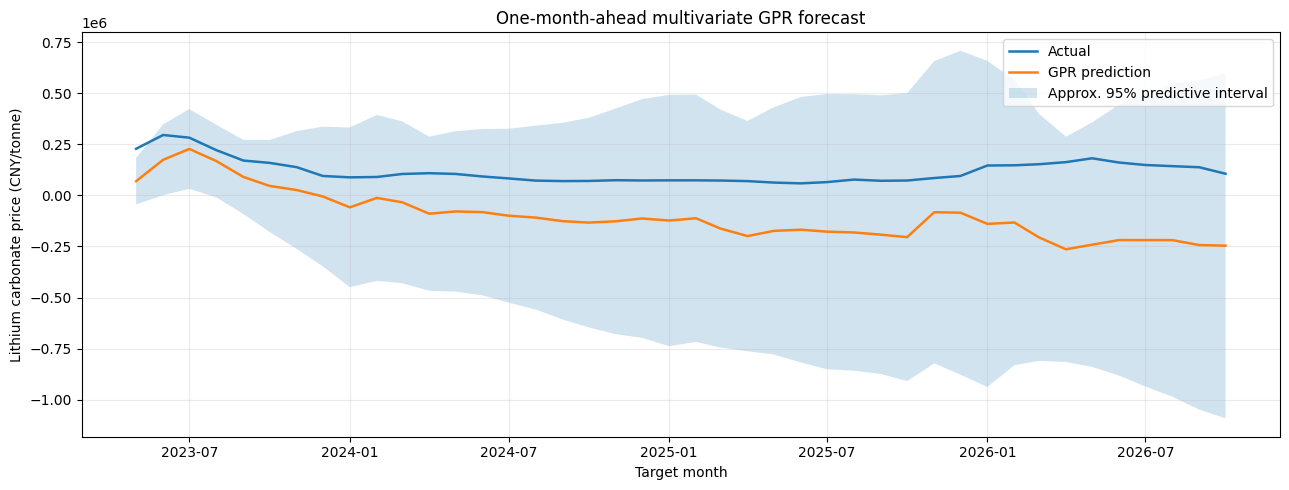

Empirical test coverage of approximate 95% interval: 97.6%
Optimized kernel: 10**2 * Matern(length_scale=49.9, nu=1.5) + WhiteKernel(noise_level=0.00122)


In [49]:
h = 1
feature_set = "Multivariate (3 lags; top 5 predictors)"
y_test, pred, std, fitted_gpr = predictions[(feature_set, h)]

lower = pred - 1.96 * std
upper = pred + 1.96 * std

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(y_test.index, y_test.values, label="Actual", linewidth=1.8)
ax.plot(y_test.index, pred, label="GPR prediction", linewidth=1.8)
ax.fill_between(y_test.index, lower, upper, alpha=0.2, label="Approx. 95% predictive interval")
ax.set(
    title="One-month-ahead multivariate GPR forecast",
    xlabel="Target month",
    ylabel="Lithium carbonate price (CNY/tonne)"
)
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

coverage_95 = np.mean((y_test.values >= lower) & (y_test.values <= upper))
print(f"Empirical test coverage of approximate 95% interval: {coverage_95:.1%}")
print("Optimized kernel:", fitted_gpr.named_steps["gpr"].kernel_)

In [52]:
lower = pred - 1.96 * std
upper = pred + 1.96 * std

coverage = np.mean(
    (y_test.values >= lower) &
    (y_test.values <= upper)
)

mean_width = np.mean(upper - lower)

print("GPR empirical coverage:", coverage)
print("Average interval width:", mean_width)

GPR empirical coverage: 0.9761904761904762
Average interval width: 1048328.3859667818


## 7. Residual diagnostics

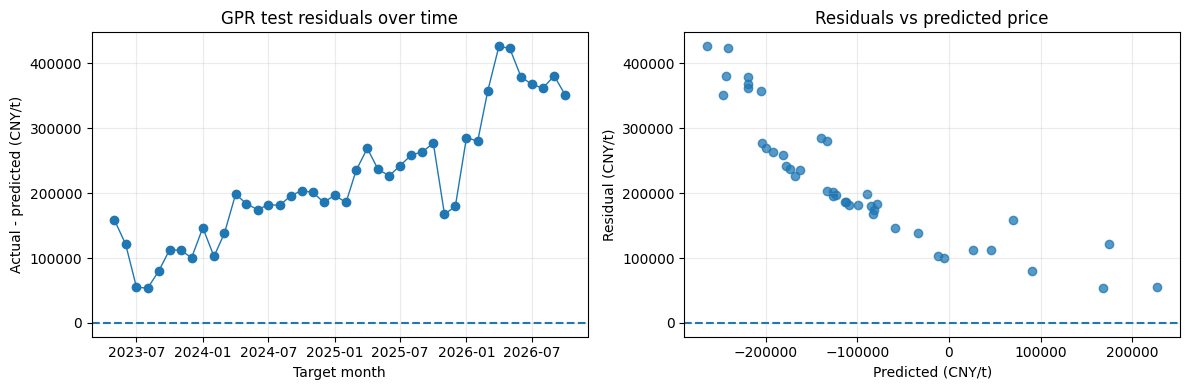

In [50]:
residuals = y_test.values - pred

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(y_test.index, residuals, marker="o", linewidth=1)
axes[0].axhline(0, linestyle="--")
axes[0].set(title="GPR test residuals over time", xlabel="Target month", ylabel="Actual - predicted (CNY/t)")
axes[0].grid(alpha=0.25)

axes[1].scatter(pred, residuals, alpha=0.75)
axes[1].axhline(0, linestyle="--")
axes[1].set(title="Residuals vs predicted price", xlabel="Predicted (CNY/t)", ylabel="Residual (CNY/t)")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

## 8. Save results

In [51]:
results.to_csv("../../Results/gaussian_process_model_comparison.csv", index=False)
print("Saved ../../Results/gaussian_process_model_comparison.csv")

Saved ../../Results/gaussian_process_model_comparison.csv
